# Day 14 — Decision trees, splits, depth and overfitting

Run each cell with **Shift + Enter**, from the top. We use scikit-learn's Iris dataset and our 150-student dataset, `student_data_150.csv`: 8 real students and 142 **synthetic** ones.

## 1. Introduction and intuition

In [ ]:
# Get the student dataset: Colab starts with an empty folder. If the download fails, upload student_data_150.csv
# with the Files panel (the folder icon on the left) and run this cell again. (Iris ships with scikit-learn.)
import os
import urllib.request

URL = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-014/data/student_data_150.csv"
if not os.path.exists("student_data_150.csv"):
    urllib.request.urlretrieve(URL, "student_data_150.csv")

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Your first decision tree: the Iris flowers (150 flowers, 4 measurements, 3 species)
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Train {len(X_train)} | test {len(X_test)}")
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))

Train 120 | test 30
Accuracy: 0.967


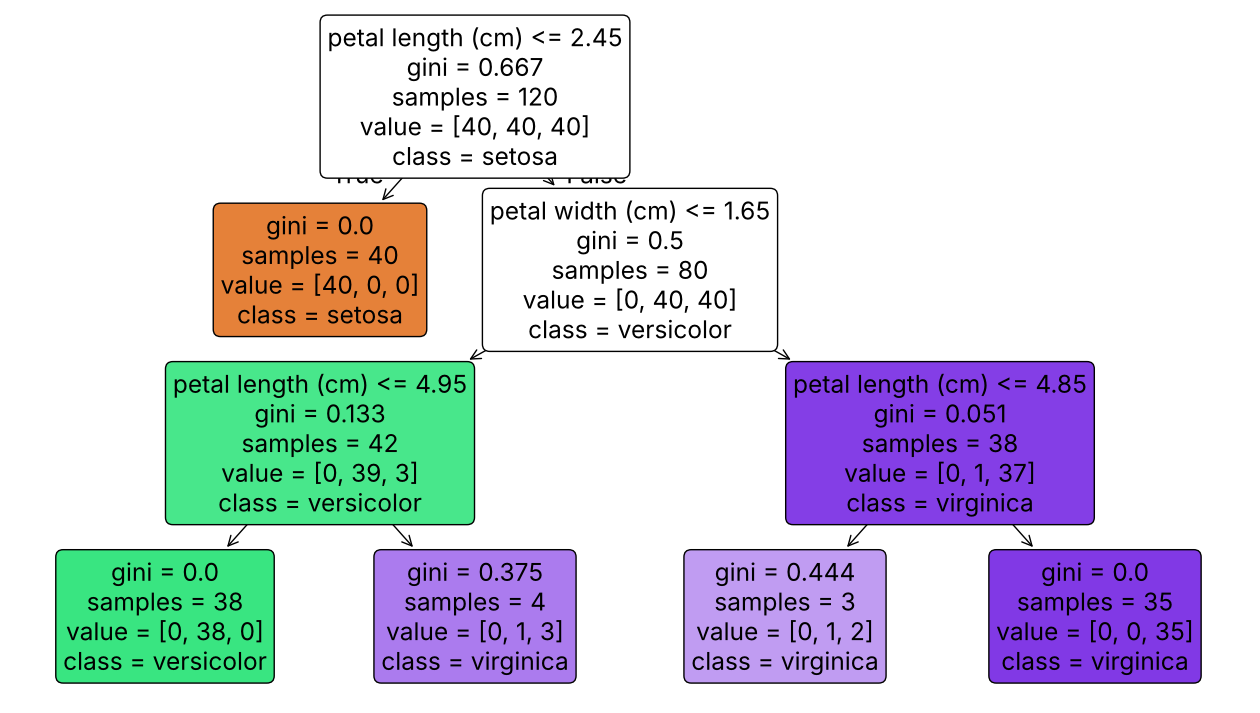

|--- petal length (cm) <= 2.45
|   |--- weights: [40.00, 0.00, 0.00] class: setosa
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.65
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- weights: [0.00, 38.00, 0.00] class: versicolor
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- weights: [0.00, 1.00, 3.00] class: virginica
|   |--- petal width (cm) >  1.65
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- weights: [0.00, 1.00, 2.00] class: virginica
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- weights: [0.00, 0.00, 35.00] class: virginica

Depth 3 | leaves 5


In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

# Visualize the trained tree: plot_tree draws it; export_text prints the same rules as text
plt.figure(figsize=(16, 9))
plot_tree(model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True)
plt.show()
print(export_text(model, feature_names=iris.feature_names, class_names=list(iris.target_names), show_weights=True))
print(f"Depth {model.get_depth()} | leaves {model.get_n_leaves()}")

In [ ]:
import pandas as pd

# A student tree: will a student pass? Fitted on 127 students; 23 more are kept aside as a test set for Section 5
df = pd.read_csv("student_data_150.csv")
features = ["StudyHours", "Attendance", "PreviousScore"]
train_val, test = train_test_split(df, test_size=0.15, random_state=42, stratify=df["Passed"])
student_tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(train_val[features], train_val["Passed"])
print(export_text(student_tree, feature_names=features, class_names=["Fail", "Pass"], show_weights=True))
print(f"Training accuracy {accuracy_score(train_val['Passed'], student_tree.predict(train_val[features])):.3f} (the test comes in Section 5)")

|--- StudyHours <= 2.75
|   |--- PreviousScore <= 46.50
|   |   |--- weights: [10.00, 0.00] class: Fail
|   |--- PreviousScore >  46.50
|   |   |--- weights: [11.00, 13.00] class: Pass
|--- StudyHours >  2.75
|   |--- Attendance <= 81.50
|   |   |--- weights: [14.00, 34.00] class: Pass
|   |--- Attendance >  81.50
|   |   |--- weights: [2.00, 43.00] class: Pass

Training accuracy 0.787 (the test comes in Section 5)


In [ ]:
# Practice preview: deeper isn't automatically better. Iris trees at max_depth 2, 3 and 5
for depth in [2, 3, 5]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    print(f"max_depth={depth}: leaves {m.get_n_leaves():2d} | train accuracy {accuracy_score(y_train, m.predict(X_train)):.3f}"
          f" | test accuracy {accuracy_score(y_test, m.predict(X_test)):.3f}")

max_depth=2: leaves  3 | train accuracy 0.967 | test accuracy 0.933
max_depth=3: leaves  5 | train accuracy 0.983 | test accuracy 0.967
max_depth=5: leaves  8 | train accuracy 1.000 | test accuracy 0.933


## 2. Split criteria: Gini and entropy

In [ ]:
import numpy as np

# Section 2: impurity by hand. Gini = 1 - sum(p^2); entropy = -sum(p log2 p)
def gini(counts):
    p = np.array(counts) / sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.array(counts) / sum(counts)
    p = p[p > 0]                                   # 0 x log(0) counts as 0
    return -np.sum(p * np.log2(p)) + 0.0           # + 0.0 turns -0.0 into 0.0

def gains(parent, children):
    n = sum(parent)
    w_gini = sum(sum(c) / n * gini(c) for c in children)
    w_entropy = sum(sum(c) / n * entropy(c) for c in children)
    return w_gini, gini(parent) - w_gini, w_entropy, entropy(parent) - w_entropy

parent = [6, 4]                                    # 6 pass, 4 fail
print(f"Parent: Gini {gini(parent):.2f} | entropy {entropy(parent):.3f}")
for name, children in [("Split A: [2, 3] and [4, 1]", [[2, 3], [4, 1]]), ("Split B: [3, 2] and [3, 2]", [[3, 2], [3, 2]])]:
    wg, gg, we, ig = gains(parent, children)
    print(f"{name}: weighted Gini {wg:.2f} (gain {gg:.2f}) | weighted entropy {we:.3f} (information gain {ig:.3f})")

Parent: Gini 0.48 | entropy 0.971
Split A: [2, 3] and [4, 1]: weighted Gini 0.40 (gain 0.08) | weighted entropy 0.846 (information gain 0.125)
Split B: [3, 2] and [3, 2]: weighted Gini 0.48 (gain 0.00) | weighted entropy 0.971 (information gain 0.000)


In [ ]:
# Quick practice: Gini and entropy for different class mixes
for counts in [[7, 3], [5, 5], [9, 1], [10, 0]]:
    print(f"{str(counts):<8} Gini {gini(counts):.3f} | entropy {entropy(counts):.3f}")
curve = pd.DataFrame({"p": np.round(np.arange(0, 1.0001, 0.05), 2)})
curve["Gini"] = (1 - curve["p"] ** 2 - (1 - curve["p"]) ** 2).round(3)
curve["Entropy"] = [round(entropy([q, 1 - q]), 3) for q in curve["p"]]
curve.to_csv("impurity_curve.csv", index=False)

[7, 3]   Gini 0.420 | entropy 0.881
[5, 5]   Gini 0.500 | entropy 1.000
[9, 1]   Gini 0.180 | entropy 0.469
[10, 0]  Gini 0.000 | entropy 0.000


In [ ]:
# On our students: try EVERY threshold of every feature at the root, as the tree does (the 127 training students)
y_tv = train_val["Passed"].astype(int).values
root = [int((y_tv == 0).sum()), int((y_tv == 1).sum())]
print(f"Root: {root[0]} fail, {root[1]} pass | Gini {gini(root):.3f} | entropy {entropy(root):.3f}")
rows = []
for f in features:
    values = np.sort(train_val[f].unique())
    for t in (values[:-1] + values[1:]) / 2:       # midpoints between neighbouring values, like scikit-learn
        left = y_tv[train_val[f] <= t]
        right = y_tv[train_val[f] > t]
        _, gg, _, ig = gains(root, [[(left == 0).sum(), (left == 1).sum()], [(right == 0).sum(), (right == 1).sum()]])
        rows.append({"Feature": f, "Threshold": round(t, 2), "GiniGain": round(gg, 4), "InfoGain": round(ig, 4)})
splits = pd.DataFrame(rows)
for f in features:
    best = splits[splits["Feature"] == f].sort_values("GiniGain", ascending=False).iloc[0]
    print(f"Best {f:<13} <= {best['Threshold']:6.2f} | Gini gain {best['GiniGain']:.4f} | information gain {best['InfoGain']:.4f}")
mock = splits[(splits["Feature"] == "StudyHours") & (splits["Threshold"] == 4.75)].iloc[0]
print(f"StudyHours <= 4.5 (the mock's question): Gini gain {mock['GiniGain']:.4f} | information gain {mock['InfoGain']:.4f}")
splits[splits["Feature"] == "StudyHours"][["Threshold", "GiniGain", "InfoGain"]].to_csv("study_hours_splits.csv", index=False)

Root: 37 fail, 90 pass | Gini 0.413 | entropy 0.870
Best StudyHours    <=   2.75 | Gini gain 0.0779 | information gain 0.1285
Best Attendance    <=  76.50 | Gini gain 0.0495 | information gain 0.0855
Best PreviousScore <=  47.50 | Gini gain 0.0639 | information gain 0.1018
StudyHours <= 4.5 (the mock's question): Gini gain 0.0329 | information gain 0.0750


In [ ]:
# Do Gini and entropy pick the same root? Depth-1 trees ("stumps") with each criterion
for criterion in ["gini", "entropy"]:
    stump = DecisionTreeClassifier(max_depth=1, criterion=criterion, random_state=42).fit(train_val[features], train_val["Passed"])
    print(f"{criterion:<8}", export_text(stump, feature_names=features).splitlines()[0].strip())

gini     |--- StudyHours <= 2.75
entropy  |--- StudyHours <= 2.75


## 3. Tree depth and overfitting

In [ ]:
# Section 3: the effect of depth on Iris (the same 120/30 split as Section 1)
for depth in [1, 2, 3, 5, 10, None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    print(f"Depth: {str(depth):<4} actual {m.get_depth()} | leaves {m.get_n_leaves():2d} | "
          f"Train: {accuracy_score(y_train, m.predict(X_train)):.3f}, Test: {accuracy_score(y_test, m.predict(X_test)):.3f}")

Depth: 1    actual 1 | leaves  2 | Train: 0.667, Test: 0.667
Depth: 2    actual 2 | leaves  3 | Train: 0.967, Test: 0.933
Depth: 3    actual 3 | leaves  5 | Train: 0.983, Test: 0.967
Depth: 5    actual 5 | leaves  8 | Train: 1.000, Test: 0.933
Depth: 10   actual 5 | leaves  8 | Train: 1.000, Test: 0.933
Depth: None actual 5 | leaves  8 | Train: 1.000, Test: 0.933


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# On our students: training accuracy vs 5-fold cross-validated accuracy as depth grows (the 127; the test set waits)
y_s = train_val["Passed"]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Always guessing 'pass': {y_s.mean():.3f}")
rows = []
for depth in list(range(1, 11)) + [None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42)
    cv = cross_val_score(m, train_val[features], y_s, cv=cv5)
    m.fit(train_val[features], y_s)
    rows.append({"Depth": depth if depth else m.get_depth(), "Leaves": m.get_n_leaves(),
                 "TrainAccuracy": round(accuracy_score(y_s, m.predict(train_val[features])), 3),
                 "CVAccuracy": round(cv.mean(), 3), "CVStd": round(cv.std(), 3)})
    print(f"max_depth={str(depth):<4} leaves {m.get_n_leaves():3d} | train {rows[-1]['TrainAccuracy']:.3f} | "
          f"CV {cv.mean():.3f} +/- {cv.std():.3f}")
depth_curve = pd.DataFrame(rows[:-1])                  # depths 1-10 for the chart
depth_curve.to_csv("student_depth.csv", index=False)

Always guessing 'pass': 0.709
max_depth=1    leaves   2 | train 0.772 | CV 0.709 +/- 0.035
max_depth=2    leaves   4 | train 0.787 | CV 0.740 +/- 0.039
max_depth=3    leaves   7 | train 0.819 | CV 0.717 +/- 0.028
max_depth=4    leaves  11 | train 0.843 | CV 0.725 +/- 0.022
max_depth=5    leaves  14 | train 0.866 | CV 0.709 +/- 0.052


max_depth=6    leaves  18 | train 0.913 | CV 0.725 +/- 0.059


max_depth=7    leaves  23 | train 0.945 | CV 0.717 +/- 0.044


max_depth=8    leaves  28 | train 0.976 | CV 0.717 +/- 0.065


max_depth=9    leaves  31 | train 0.992 | CV 0.725 +/- 0.059


max_depth=10   leaves  32 | train 0.992 | CV 0.710 +/- 0.070


max_depth=None leaves  33 | train 1.000 | CV 0.717 +/- 0.065


In [ ]:
# Another control: min_samples_leaf (no depth limit). Bigger leaves = fewer, more reliable rules
for leaf in [1, 5, 10, 20]:
    m = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=42)
    cv = cross_val_score(m, train_val[features], y_s, cv=cv5)
    m.fit(train_val[features], y_s)
    print(f"min_samples_leaf={leaf:<3} depth {m.get_depth():2d} | leaves {m.get_n_leaves():3d} | "
          f"train {accuracy_score(y_s, m.predict(train_val[features])):.3f} | CV {cv.mean():.3f} +/- {cv.std():.3f}")

min_samples_leaf=1   depth 11 | leaves  33 | train 1.000 | CV 0.717 +/- 0.065
min_samples_leaf=5   depth  6 | leaves  13 | train 0.858 | CV 0.740 +/- 0.039
min_samples_leaf=10  depth  4 | leaves   8 | train 0.819 | CV 0.709 +/- 0.038
min_samples_leaf=20  depth  3 | leaves   5 | train 0.772 | CV 0.725 +/- 0.030


## 4. Pruning and hyperparameters

In [ ]:
from sklearn.model_selection import GridSearchCV

# Section 4: hyperparameter tuning on Iris with cross-validation on the TRAINING data; the test set is used once
parameters = {"max_depth": [2, 3, 5, 10, None], "min_samples_split": [2, 5, 10],
              "min_samples_leaf": [1, 2, 5], "criterion": ["gini", "entropy"]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), parameters, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)
print(f"Combinations tried: {len(grid.cv_results_['params'])}")
print("Best parameters:", grid.best_params_)
print(f"Best CV score: {grid.best_score_:.3f}")
print(f"Test score: {grid.score(X_test, y_test):.3f}")
ties = (grid.cv_results_["mean_test_score"] == grid.best_score_).sum()
print(f"Combinations tied for the best CV score: {ties}")

Combinations tried: 90
Best parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV score: 0.942
Test score: 0.933
Combinations tied for the best CV score: 3


In [ ]:
# Pre-pruning vs post-pruning on our students (5-fold CV on the 127; the test set waits for Section 5)
settings = {"No pruning": DecisionTreeClassifier(random_state=42),
            "Pre-pruning: depth 4, split 10, leaf 5": DecisionTreeClassifier(max_depth=4, min_samples_split=10,
                                                                               min_samples_leaf=5, random_state=42),
            "Post-pruning: ccp_alpha 0.01": DecisionTreeClassifier(ccp_alpha=0.01, random_state=42)}
for name, m in settings.items():
    cv = cross_val_score(m, train_val[features], y_s, cv=cv5)
    m.fit(train_val[features], y_s)
    print(f"{name:<38} leaves {m.get_n_leaves():2d} | train {accuracy_score(y_s, m.predict(train_val[features])):.3f} | "
          f"CV {cv.mean():.3f} +/- {cv.std():.3f}")

No pruning                             leaves 33 | train 1.000 | CV 0.717 +/- 0.065
Pre-pruning: depth 4, split 10, leaf 5 leaves  9 | train 0.827 | CV 0.709 +/- 0.014
Post-pruning: ccp_alpha 0.01           leaves 19 | train 0.913 | CV 0.717 +/- 0.044


In [ ]:
# The cost-complexity pruning path: each ccp_alpha removes the weakest branches of the full tree
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(train_val[features], y_s)
rows = []
for alpha in path.ccp_alphas[:-1]:                     # the last alpha prunes everything down to the root
    m = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    cv = cross_val_score(m, train_val[features], y_s, cv=cv5)
    m.fit(train_val[features], y_s)
    rows.append({"Alpha": round(alpha, 4), "Leaves": m.get_n_leaves(),
                 "TrainAccuracy": round(accuracy_score(y_s, m.predict(train_val[features])), 3), "CVAccuracy": round(cv.mean(), 3)})
pruning = pd.DataFrame(rows).drop_duplicates("Leaves")
print(pruning.iloc[::3].to_string(index=False))
best = pruning.loc[pruning["CVAccuracy"].idxmax()]
print(f"Best CV accuracy {best['CVAccuracy']:.3f} at ccp_alpha {best['Alpha']:.4f} with {int(best['Leaves'])} leaves")
pruning.to_csv("pruning_path.csv", index=False)

 Alpha  Leaves  TrainAccuracy  CVAccuracy
0.0000      33          1.000       0.717
0.0063      23          0.953       0.725
0.0100      17          0.906       0.717
0.0120       8          0.843       0.709
0.0177       4          0.787       0.733
Best CV accuracy 0.749 at ccp_alpha 0.0224 with 3 leaves


## 5. End-to-end example: student pass/fail

In [ ]:
# Section 5, end to end. 1-2. Problem and exploration: predict Pass (1) or Fail (0)
df = pd.read_csv("student_data_150.csv")
df["Result"] = np.where(df["Passed"], "Pass", "Fail")
print(f"Shape {df.shape} | missing values {df.isna().sum().sum()} | synthetic {(df['Source'] != 'original').sum()} of {len(df)}")
print(df["Result"].value_counts().to_string())
print(df.groupby("Result")["StudyHours"].describe()[["mean", "25%", "50%", "75%"]].round(2).to_string())
df["AttendanceGroup"] = pd.cut(df["Attendance"], [0, 75, 85, 101], right=False, labels=["1: under 75%", "2: 75-85%", "3: 85%+"])
rate = df.groupby("AttendanceGroup", observed=True)["Passed"].agg(["mean", "size"])
print("Pass rate by attendance:", {g: f"{r['mean']:.0%} of {int(r['size'])}" for g, r in rate.iterrows()})
df.assign(Pass=df["Passed"].astype(int))[["StudyHours", "Result", "AttendanceGroup", "Pass"]].to_csv("eda.csv", index=False)

Shape (150, 10) | missing values 0 | synthetic 142 of 150
Result
Pass    106
Fail     44
        mean   25%  50%   75%
Result                       
Fail    2.57  1.50  2.5  3.50
Pass    3.99  3.12  4.0  4.88
Pass rate by attendance: {'1: under 75%': '53% of 49', '2: 75-85%': '71% of 55', '3: 85%+': '89% of 46'}


In [ ]:
# 3. Train and compare trees on the 127 (the 23 test students stay untouched): training vs 5-fold CV accuracy
train_val, test = train_test_split(df, test_size=0.15, random_state=42, stratify=df["Passed"])
y_tv, y_te = train_val["Passed"].astype(int), test["Passed"].astype(int)
for depth in [1, 3, 5, 10, None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42)
    cv = cross_val_score(m, train_val[features], y_tv, cv=cv5)
    m.fit(train_val[features], y_tv)
    print(f"max_depth={str(depth):<4} train {accuracy_score(y_tv, m.predict(train_val[features])):.3f} | CV {cv.mean():.3f} +/- {cv.std():.3f}")

max_depth=1    train 0.772 | CV 0.709 +/- 0.035
max_depth=3    train 0.819 | CV 0.717 +/- 0.028
max_depth=5    train 0.866 | CV 0.709 +/- 0.052
max_depth=10   train 0.992 | CV 0.710 +/- 0.070
max_depth=None train 1.000 | CV 0.717 +/- 0.065


In [ ]:
# 4. Tune with cross-validation on the 127, scored by F1 for Pass (the lesson's grid, with ccp_alpha)
param_grid = {"max_depth": [2, 3, 5, 10, None], "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 5],
              "criterion": ["gini", "entropy"], "ccp_alpha": [0.0, 0.001, 0.01]}
tuned = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=cv5, scoring="f1", n_jobs=-1)
tuned.fit(train_val[features], y_tv)
best_model = tuned.best_estimator_
print(f"Combinations: {len(tuned.cv_results_['params'])}")
print("Best parameters:", tuned.best_params_)
print(f"Best CV F1: {tuned.best_score_:.3f} | depth {best_model.get_depth()} | leaves {best_model.get_n_leaves()}")

Combinations: 270
Best parameters: {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV F1: 0.844 | depth 5 | leaves 10


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# 5. Evaluate ONCE on the 23 test students. For the school, recall for Fail matters most: a missed student gets no help
predictions = best_model.predict(test[features])
print(classification_report(y_te, predictions, target_names=["Fail", "Pass"], digits=2))
tn, fp, fn, tp = confusion_matrix(y_te, predictions).ravel()
print(f"Fail students caught: {tn} of {tn + fp} | passing students wrongly flagged as fail: {fn}")

              precision    recall  f1-score   support

        Fail       0.75      0.43      0.55         7
        Pass       0.79      0.94      0.86        16

    accuracy                           0.78        23
   macro avg       0.77      0.68      0.70        23
weighted avg       0.78      0.78      0.76        23

Fail students caught: 3 of 7 | passing students wrongly flagged as fail: 1


In [ ]:
# 6. Interpret the chosen tree: its rules and which features it uses
print(export_text(best_model, feature_names=features, class_names=["Fail", "Pass"]))
for f, imp in sorted(zip(features, best_model.feature_importances_), key=lambda t: -t[1]):
    print(f"{f:<14} importance {imp:.2f}")

|--- StudyHours <= 2.75
|   |--- PreviousScore <= 46.50
|   |   |--- class: Fail
|   |--- PreviousScore >  46.50
|   |   |--- StudyHours <= 1.75
|   |   |   |--- class: Fail
|   |   |--- StudyHours >  1.75
|   |   |   |--- Attendance <= 70.50
|   |   |   |   |--- class: Fail
|   |   |   |--- Attendance >  70.50
|   |   |   |   |--- PreviousScore <= 54.50
|   |   |   |   |   |--- class: Pass
|   |   |   |   |--- PreviousScore >  54.50
|   |   |   |   |   |--- class: Pass
|--- StudyHours >  2.75
|   |--- Attendance <= 84.50
|   |   |--- PreviousScore <= 83.50
|   |   |   |--- PreviousScore <= 47.50
|   |   |   |   |--- class: Fail
|   |   |   |--- PreviousScore >  47.50
|   |   |   |   |--- PreviousScore <= 56.00
|   |   |   |   |   |--- class: Pass
|   |   |   |   |--- PreviousScore >  56.00
|   |   |   |   |   |--- class: Pass
|   |   |--- PreviousScore >  83.50
|   |   |   |--- class: Pass
|   |--- Attendance >  84.50
|   |   |--- class: Pass

PreviousScore  importance 0.43
StudyHours

## 6. Mini project: pass/fail tree for the school's goal

In [ ]:
from sklearn.metrics import make_scorer, f1_score, recall_score

# Section 6 mini project. Pruning on the 127: what each ccp_alpha does to size, accuracy and recall for FAIL
fail_recall = make_scorer(recall_score, pos_label=0)
for alpha in [0.0, 0.001, 0.01, 0.1]:
    m = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    acc = cross_val_score(m, train_val[features], y_tv, cv=cv5).mean()
    rec = cross_val_score(m, train_val[features], y_tv, cv=cv5, scoring=fail_recall).mean()
    m.fit(train_val[features], y_tv)
    print(f"ccp_alpha={alpha:<5} leaves {m.get_n_leaves():2d} | train {accuracy_score(y_tv, m.predict(train_val[features])):.3f} | "
          f"CV accuracy {acc:.3f} | CV recall for fail {rec:.3f}")

ccp_alpha=0.0   leaves 33 | train 1.000 | CV accuracy 0.717 | CV recall for fail 0.489
ccp_alpha=0.001 leaves 33 | train 1.000 | CV accuracy 0.717 | CV recall for fail 0.489
ccp_alpha=0.01  leaves 19 | train 0.913 | CV accuracy 0.717 | CV recall for fail 0.489
ccp_alpha=0.1   leaves  1 | train 0.709 | CV accuracy 0.709 | CV recall for fail 0.000


In [ ]:
# Tune for the school's goal, fixed BEFORE looking at any test result: F1 for the Fail class (balances catching
# failing students with not flagging everyone). The lesson's grid
fail_f1 = make_scorer(f1_score, pos_label=0)
grid_fail = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         {"max_depth": [2, 3, 5, 10], "min_samples_leaf": [1, 2, 5],
                          "ccp_alpha": [0.0, 0.001, 0.01], "criterion": ["gini", "entropy"]},
                         cv=cv5, scoring=fail_f1, n_jobs=-1).fit(train_val[features], y_tv)
project_tree = grid_fail.best_estimator_
print(f"Combinations: {len(grid_fail.cv_results_['params'])}")
print("Best parameters:", grid_fail.best_params_)
print(f"Best CV F1 for fail: {grid_fail.best_score_:.3f} | depth {project_tree.get_depth()} | leaves {project_tree.get_n_leaves()}")

Combinations: 72
Best parameters: {'ccp_alpha': 0.0, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 2}
Best CV F1 for fail: 0.565 | depth 5 | leaves 11


In [ ]:
from sklearn.model_selection import cross_val_predict

# Evaluate. Out-of-fold on the 127 (every student predicted by a tree that never saw them)...
oof_pred = cross_val_predict(DecisionTreeClassifier(random_state=42, **grid_fail.best_params_), train_val[features], y_tv, cv=cv5)
print(classification_report(y_tv, oof_pred, target_names=["Fail", "Pass"], digits=2))
# ...and a SECOND look at the 23 test students (Section 5 already used them once, so this is not an untouched test)
test_pred = project_tree.predict(test[features])
tn, fp, fn, tp = confusion_matrix(y_te, test_pred).ravel()
print(f"Test (second look): fail students caught {tn} of {tn + fp} (Section 5's tree: 3) | passing flagged as fail {fn} | accuracy {accuracy_score(y_te, test_pred):.2f}")

              precision    recall  f1-score   support

        Fail       0.56      0.59      0.58        37
        Pass       0.83      0.81      0.82        90

    accuracy                           0.75       127
   macro avg       0.70      0.70      0.70       127
weighted avg       0.75      0.75      0.75       127

Test (second look): fail students caught 3 of 7 (Section 5's tree: 3) | passing flagged as fail 0 | accuracy 0.83


In [ ]:
# Interpret the project tree: its rules and feature importances
print(export_text(project_tree, feature_names=features, class_names=["Fail", "Pass"]))
for f, imp in sorted(zip(features, project_tree.feature_importances_), key=lambda t: -t[1]):
    print(f"{f:<14} importance {imp:.2f}")

|--- StudyHours <= 2.75
|   |--- PreviousScore <= 46.50
|   |   |--- class: Fail
|   |--- PreviousScore >  46.50
|   |   |--- PreviousScore <= 68.50
|   |   |   |--- StudyHours <= 1.25
|   |   |   |   |--- class: Fail
|   |   |   |--- StudyHours >  1.25
|   |   |   |   |--- Attendance <= 76.00
|   |   |   |   |   |--- class: Fail
|   |   |   |   |--- Attendance >  76.00
|   |   |   |   |   |--- class: Pass
|   |   |--- PreviousScore >  68.50
|   |   |   |--- class: Pass
|--- StudyHours >  2.75
|   |--- Attendance <= 84.50
|   |   |--- PreviousScore <= 83.50
|   |   |   |--- PreviousScore <= 47.50
|   |   |   |   |--- StudyHours <= 3.25
|   |   |   |   |   |--- class: Fail
|   |   |   |   |--- StudyHours >  3.25
|   |   |   |   |   |--- class: Fail
|   |   |   |--- PreviousScore >  47.50
|   |   |   |   |--- PreviousScore <= 56.00
|   |   |   |   |   |--- class: Pass
|   |   |   |   |--- PreviousScore >  56.00
|   |   |   |   |   |--- class: Pass
|   |   |--- PreviousScore >  83.50
|   